# Viability Threshold Sensitivity Analysis

The baseline simulation filters rolled attribute arrays with two author-defined criteria:
- **Peak threshold:** at least one attribute ≥ 16
- **Average threshold:** mean attribute score ≥ 12

This notebook varies both thresholds across a grid to test how sensitive the demographic findings are to these design choices.

**Important caveat:** The ≥16 check also appears inside `get_stat_combos()` (class selection requires highest stat ≥ 16) and `query_skills()` (background selection requires at least one stat ≥ 16). These are part of the class/background selection mechanics, not the viability pre-filter, and are held constant here. This means lowering the peak threshold in the pre-filter primarily affects dead-farmer counts and the proportion of arrays that reach class selection — characters that still fail `get_stat_combos` will be retried via the outer generation loop.

In [1]:
import random
import pickle
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.stats import entropy as scipy_entropy
from tqdm import tqdm
import gen as g

## 1. Parametrized Generation Functions

In [2]:
def roll_stats_thresh(min_peak, min_avg):
    """Roll stats with configurable viability thresholds.

    min_peak: minimum value required for at least one stat (None = no filter).
    min_avg:  minimum required mean attribute score.
    Returns (stats_dict, n_failed_rolls).
    """
    rolled_stats = {}
    roll_count = 0
    while True:
        for i in range(6):
            rolled_stats[i] = g.roll_3d6()
        avg = sum(rolled_stats.values()) / 6
        peak_ok = (min_peak is None) or any(v >= min_peak for v in rolled_stats.values())
        if avg >= min_avg and peak_ok:
            break
        roll_count += 1
    return rolled_stats, roll_count


def generate_thresh(min_peak, min_avg):
    """Full character generation with configurable viability thresholds.

    Counts all failed attempts (roll_stats failures and outer-loop retries)
    as dead farmers, which feed directly into alignment determination.
    """
    dead_farmers = 0
    while True:
        stats, attempts = roll_stats_thresh(min_peak, min_avg)
        dead_farmers += attempts
        species = g.recommend_species(stats)
        updated = g.apply_species_bonus(stats, species)
        optimal = g.sort_stats(updated)
        chosen_class = g.select_class(optimal)
        background = g.pick_background(optimal)
        if species and chosen_class and background:
            break
        dead_farmers += 1  # outer-loop retry counts as a dead farmer
    alignment = g.determine_alignment(dead_farmers)
    return species, chosen_class, alignment, dead_farmers


def run_thresh_simulation(min_peak, min_avg, n_sims, n_chars):
    results = []
    for _ in range(n_sims):
        species_count    = {}
        class_count      = {}
        alignment_count  = {}
        df_total = 0
        for _ in range(n_chars):
            sp, cl, al, df = generate_thresh(min_peak, min_avg)
            species_count[sp] = species_count.get(sp, 0) + 1
            class_count[cl]   = class_count.get(cl, 0) + 1
            alignment_count[al] = alignment_count.get(al, 0) + 1
            df_total += df
        results.append((species_count, class_count, alignment_count, df_total / n_chars))
    return results

## 2. Define Threshold Grid and Run

In [3]:
PEAK_THRESHOLDS = [None, 14, 16, 18]   # None = no pre-filter
AVG_THRESHOLDS  = [11, 12, 13]         # 8/9/10 pass almost every roll (below expected 4d6-drop-lowest mean ~12.2)
N_SIMS  = 5
N_CHARS = 500    # 5 x 500 = 2,500 per combo; enough to see structural trends, ~12 min total
CACHE   = 'threshold_sensitivity_results.pkl'

HUMAN_ADJACENT = {'Human', 'Human Variant', 'Half-Elf'}  # Half-Orc has fixed +2 STR/+1 CON — not flexible

if os.path.exists(CACHE):
    with open(CACHE, 'rb') as f:
        all_results = pickle.load(f)
    print(f"Loaded cached results from {CACHE}")
else:
    all_results = {}
    combos = list(itertools.product(PEAK_THRESHOLDS, AVG_THRESHOLDS))
    print(f"Running {len(combos)} combinations × {N_SIMS} sims × {N_CHARS} chars = "
          f"{len(combos) * N_SIMS * N_CHARS:,} total characters")
    for peak, avg in tqdm(combos, desc='Threshold combinations'):
        key = (peak, avg)
        all_results[key] = run_thresh_simulation(peak, avg, N_SIMS, N_CHARS)
    with open(CACHE, 'wb') as f:
        pickle.dump(all_results, f)
    print(f"Saved to {CACHE}")

Loaded cached results from threshold_sensitivity_results.pkl


## 3. Compute Metrics

In [4]:
EVIL_ALIGNMENTS = {'Lawful Evil', 'Neutral Evil', 'Chaotic Evil'}
GOOD_ALIGNMENTS = {'Lawful Good', 'Neutral Good', 'Chaotic Good'}

def compute_metrics(results):
    fighter_pcts, ha_pcts, sp_entropies, cl_entropies, df_means, evil_pcts, good_pcts = \
        [], [], [], [], [], [], []

    for species_count, class_count, alignment_count, df_mean in results:
        total = sum(class_count.values())
        al_total = sum(alignment_count.values())

        fighter_pcts.append(class_count.get('Fighter', 0) / total * 100)

        ha = sum(species_count.get(sp, 0) for sp in HUMAN_ADJACENT)
        ha_pcts.append(ha / total * 100)

        sp_vals = np.array(list(species_count.values()), dtype=float)
        sp_entropies.append(scipy_entropy(sp_vals / sp_vals.sum()))

        cl_vals = np.array(list(class_count.values()), dtype=float)
        cl_entropies.append(scipy_entropy(cl_vals / cl_vals.sum()))

        df_means.append(df_mean)

        evil = sum(alignment_count.get(a, 0) for a in EVIL_ALIGNMENTS)
        good = sum(alignment_count.get(a, 0) for a in GOOD_ALIGNMENTS)
        evil_pcts.append(evil / al_total * 100)
        good_pcts.append(good / al_total * 100)

    return {
        'fighter_mean':  np.mean(fighter_pcts),  'fighter_std':  np.std(fighter_pcts),
        'ha_mean':       np.mean(ha_pcts),        'ha_std':       np.std(ha_pcts),
        'sp_ent_mean':   np.mean(sp_entropies),   'sp_ent_std':   np.std(sp_entropies),
        'cl_ent_mean':   np.mean(cl_entropies),   'cl_ent_std':   np.std(cl_entropies),
        'df_mean':       np.mean(df_means),        'df_std':       np.std(df_means),
        'evil_mean':     np.mean(evil_pcts),       'evil_std':     np.std(evil_pcts),
        'good_mean':     np.mean(good_pcts),       'good_std':     np.std(good_pcts),
    }


metrics = {}
for (peak, avg), results in all_results.items():
    metrics[(peak, avg)] = compute_metrics(results)

baseline = metrics[(16, 12)]
print(f"Baseline (peak≥16, avg≥12):")
for k in ('fighter_mean', 'ha_mean', 'sp_ent_mean', 'cl_ent_mean', 'df_mean', 'evil_mean', 'good_mean'):
    print(f"  {k:<18} {baseline[k]:.2f}")

Baseline (peak≥16, avg≥12):
  fighter_mean       25.00
  ha_mean            36.08
  sp_ent_mean        2.60
  cl_ent_mean        2.28
  df_mean            3.71
  evil_mean          10.44
  good_mean          54.20


## 4. Heatmaps

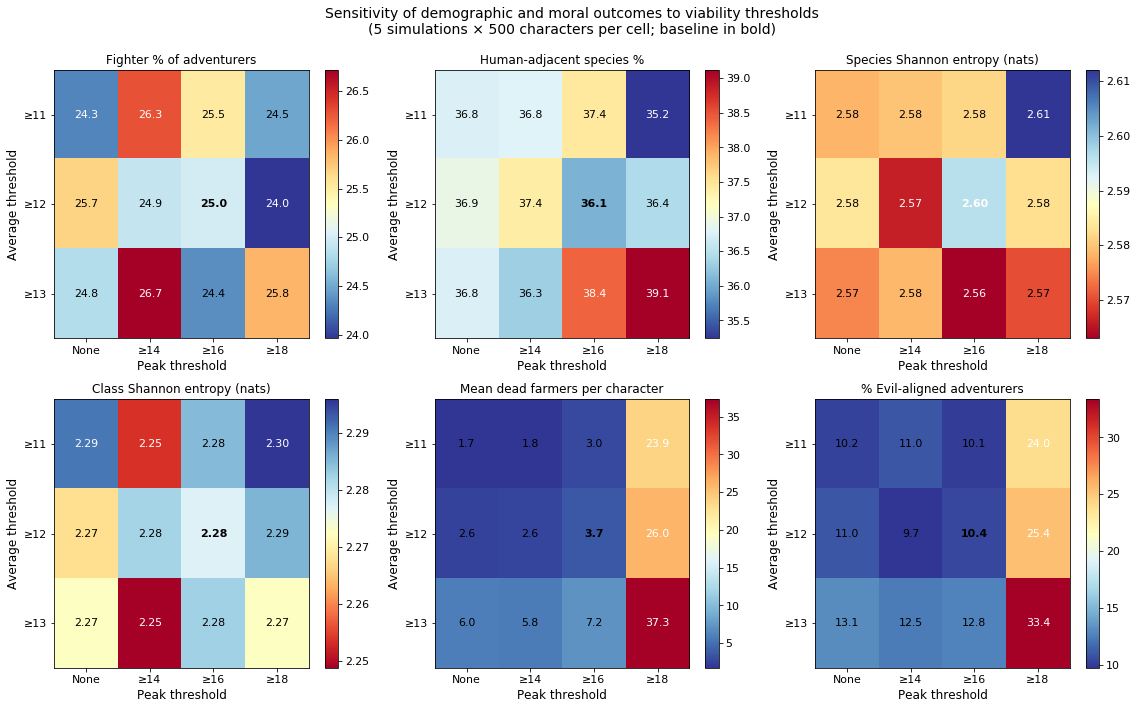

Saved to figs/threshold_sensitivity.png


In [10]:
peak_labels = ['None', '≥14', '≥16', '≥18']
avg_labels  = [f'≥{a}' for a in AVG_THRESHOLDS]

metric_keys = [
    ('fighter_mean', 'Fighter % of adventurers',        'RdYlBu_r'),
    ('ha_mean',      'Human-adjacent species %',         'RdYlBu_r'),
    ('sp_ent_mean',  'Species Shannon entropy (nats)',   'RdYlBu'),
    ('cl_ent_mean',  'Class Shannon entropy (nats)',     'RdYlBu'),
    ('df_mean',      'Mean dead farmers per character',  'RdYlBu_r'),
    ('evil_mean',    '% Evil-aligned adventurers',       'RdYlBu_r'),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (key, title, cmap) in enumerate(metric_keys):
    ax = axes[idx]
    grid = np.zeros((len(AVG_THRESHOLDS), len(PEAK_THRESHOLDS)))
    for j, peak in enumerate(PEAK_THRESHOLDS):
        for i, avg in enumerate(AVG_THRESHOLDS):
            grid[i, j] = metrics[(peak, avg)][key]

    im = ax.imshow(grid, aspect='auto', cmap=cmap)
    cb = plt.colorbar(im, ax=ax)
    cb.ax.tick_params(labelsize=11)

    ax.set_xticks(range(len(PEAK_THRESHOLDS)))
    ax.set_xticklabels(peak_labels, fontsize=11)
    ax.set_yticks(range(len(AVG_THRESHOLDS)))
    ax.set_yticklabels(avg_labels, fontsize=11)
    ax.set_xlabel('Peak threshold', fontsize=12)
    ax.set_ylabel('Average threshold', fontsize=12)
    ax.set_title(title, fontsize=12)

    for i in range(len(AVG_THRESHOLDS)):
        for j in range(len(PEAK_THRESHOLDS)):
            val = grid[i, j]
            txt = f"{val:.1f}" if key not in ('sp_ent_mean', 'cl_ent_mean') else f"{val:.2f}"
            weight = 'bold' if (PEAK_THRESHOLDS[j] == 16 and AVG_THRESHOLDS[i] == 12) else 'normal'
            ax.text(j, i, txt, ha='center', va='center', fontsize=11,
                    fontweight=weight,
                    color='white' if abs(grid[i,j] - grid.mean()) > grid.std() else 'black')

fig.suptitle(
    f'Sensitivity of demographic and moral outcomes to viability thresholds\n'
    f'({N_SIMS} simulations × {N_CHARS} characters per cell; baseline in bold)',
    fontsize=14
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('figs/threshold_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to figs/threshold_sensitivity.png")

## 5. Summary Table and Paper Numbers

In [6]:
rows = []
for peak in PEAK_THRESHOLDS:
    for avg in AVG_THRESHOLDS:
        m = metrics[(peak, avg)]
        rows.append({
            'Peak':          str(peak) if peak is not None else 'None',
            'Avg':           avg,
            'Fighter %':     f"{m['fighter_mean']:.1f} ± {m['fighter_std']:.1f}",
            'Human-adj %':   f"{m['ha_mean']:.1f} ± {m['ha_std']:.1f}",
            'Sp entropy':    f"{m['sp_ent_mean']:.2f} ± {m['sp_ent_std']:.2f}",
            'Cl entropy':    f"{m['cl_ent_mean']:.2f} ± {m['cl_ent_std']:.2f}",
            'Dead farmers':  f"{m['df_mean']:.1f} ± {m['df_std']:.1f}",
            '% Evil':        f"{m['evil_mean']:.1f} ± {m['evil_std']:.1f}",
            '% Good':        f"{m['good_mean']:.1f} ± {m['good_std']:.1f}",
        })

df_summary = pd.DataFrame(rows)
print(df_summary.to_string(index=False))

print()
for label, key in [('Fighter %', 'fighter_mean'), ('Human-adjacent %', 'ha_mean'),
                   ('% Evil', 'evil_mean'), ('% Good', 'good_mean'), ('Dead farmers', 'df_mean')]:
    vals = [metrics[k][key] for k in metrics]
    print(f"{label}: min={min(vals):.1f}  max={max(vals):.1f}  range={max(vals)-min(vals):.1f} ppts")

Peak  Avg  Fighter % Human-adj %  Sp entropy  Cl entropy Dead farmers     % Evil     % Good
None   11 24.3 ± 1.6  36.8 ± 1.5 2.58 ± 0.02 2.29 ± 0.02    1.7 ± 0.0 10.2 ± 2.2 55.7 ± 1.6
None   12 25.7 ± 1.1  36.9 ± 1.2 2.58 ± 0.01 2.27 ± 0.02    2.6 ± 0.1 11.0 ± 1.5 54.0 ± 1.2
None   13 24.8 ± 0.3  36.8 ± 2.4 2.57 ± 0.02 2.27 ± 0.01    6.0 ± 0.3 13.1 ± 1.3 53.0 ± 2.1
  14   11 26.3 ± 1.0  36.8 ± 0.6 2.58 ± 0.02 2.25 ± 0.01    1.8 ± 0.1 11.0 ± 1.4 54.6 ± 2.6
  14   12 24.9 ± 1.0  37.4 ± 1.8 2.57 ± 0.01 2.28 ± 0.01    2.6 ± 0.1  9.7 ± 1.4 55.1 ± 2.0
  14   13 26.7 ± 0.7  36.3 ± 0.9 2.58 ± 0.02 2.25 ± 0.01    5.8 ± 0.3 12.5 ± 1.5 53.2 ± 1.5
  16   11 25.5 ± 1.0  37.4 ± 0.9 2.58 ± 0.01 2.28 ± 0.02    3.0 ± 0.1 10.1 ± 1.2 57.6 ± 2.3
  16   12 25.0 ± 2.3  36.1 ± 1.7 2.60 ± 0.02 2.28 ± 0.05    3.7 ± 0.1 10.4 ± 1.6 54.2 ± 1.5
  16   13 24.4 ± 1.9  38.4 ± 2.7 2.56 ± 0.03 2.28 ± 0.04    7.2 ± 0.4 12.8 ± 1.7 51.9 ± 2.6
  18   11 24.5 ± 1.0  35.2 ± 0.9 2.61 ± 0.01 2.30 ± 0.01   23.9 ± 0.3 24.0 ± 1.4